In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
df=pd.read_csv('/content/drive/MyDrive/Advertising.csv')

In [5]:
df.head(10)

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9
5,8.7,48.9,75.0,7.2
6,57.5,32.8,23.5,11.8
7,120.2,19.6,11.6,13.2
8,8.6,2.1,1.0,4.8
9,199.8,2.6,21.2,10.6


In [6]:
X=df.drop('sales',axis=1)
X

,TV,radio,newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4
...,...,...,...
195,38.2,3.7,13.8
196,94.2,4.9,8.1
197,177.0,9.3,6.4
198,283.6,42.0,66.2


In [7]:
y=df['sales']
y

,sales
0,22.1
1,10.4
2,9.3
3,18.5
4,12.9
...,...
195,7.6
196,9.7
197,12.8
198,25.5


In [8]:
from sklearn.preprocessing import PolynomialFeatures

In [9]:
polynomial_converter = PolynomialFeatures(degree=3, include_bias=False)
poly_features = polynomial_converter.fit_transform(X)
poly_features

array([[2.30100000e+02, 3.78000000e+01, 6.92000000e+01, ...,
        9.88757280e+04, 1.81010592e+05, 3.31373888e+05],
       [4.45000000e+01, 3.93000000e+01, 4.51000000e+01, ...,
        6.96564990e+04, 7.99365930e+04, 9.17338510e+04],
       [1.72000000e+01, 4.59000000e+01, 6.93000000e+01, ...,
        1.46001933e+05, 2.20434291e+05, 3.32812557e+05],
       ...,
       [1.77000000e+02, 9.30000000e+00, 6.40000000e+00, ...,
        5.53536000e+02, 3.80928000e+02, 2.62144000e+02],
       [2.83600000e+02, 4.20000000e+01, 6.62000000e+01, ...,
        1.16776800e+05, 1.84062480e+05, 2.90117528e+05],
       [2.32100000e+02, 8.60000000e+00, 8.70000000e+00, ...,
        6.43452000e+02, 6.50934000e+02, 6.58503000e+02]])

In [10]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(poly_features,y,test_size=0.3,random_state=101)

In [11]:
X_train.shape

(140, 19)

In [12]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()
scaler.fit(X_train)

StandardScaler()

In [13]:
X_train=scaler.transform(X_train)

In [14]:
X_test=scaler.transform(X_test)

In [15]:
X_train[0]


array([ 0.49300171, -0.33994238,  1.61586707,  0.28407363, -0.02568776,
        1.49677566, -0.59023161,  0.41659155,  1.6137853 ,  0.08057172,
       -0.05392229,  1.01524393, -0.36986163,  0.52457967,  1.48737034,
       -0.66096022, -0.16360242,  0.54694754,  1.37075536])

# Ridge

In [16]:
from sklearn.linear_model import Ridge

ridge_model=Ridge(alpha=10)
ridge_model.fit(X_train,y_train)

Ridge(alpha=10)

In [17]:
riddge_model_pred=ridge_model.predict(X_test)
riddge_model_pred

array([13.7469803 , 19.17764   , 11.8623393 , 16.25574551,  8.92891155,
        8.04595366, 20.13320851, 16.94847676, 10.29219174, 19.78365691,
       10.31758361, 13.44077317, 12.24228062, 23.23864236, 19.12656362,
        9.748809  , 12.84361521,  9.14248129,  8.82504966, 21.46989971,
        8.25222201, 18.8110776 , 28.39227333, 25.06911066,  9.11912241,
       11.8071711 , 20.85199462,  9.31962495, 12.25122303,  9.07811198,
        9.25275556, 19.87154568, 10.55955497,  7.86818084, 17.67220132,
        9.31442423, 10.1539168 ,  9.47802944,  8.63337302, 10.76209179,
       11.63848891, 10.38883411, 10.90270005,  8.40019284, 11.35336224,
       10.3514086 ,  8.00082147, 15.27139854, 12.94761469, 22.49762978,
       10.80165407, 13.01337743, 14.82204895, 11.37354043, 11.69628953,
        7.20576885, 25.53512232, 10.41926545, 17.38798022, 15.10158819])

In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

MAE=mean_absolute_error(y_test,riddge_model_pred)
RMSE= np.sqrt(mean_squared_error(y_test,riddge_model_pred))
MAE,RMSE

(0.5774404204714163, np.float64(0.894638646131965))

# Ridge Cv

In [19]:
from sklearn.linear_model import RidgeCV

ridge_cv_model=RidgeCV(alphas=(0.01,0.1,1.0,10.0))
ridge_cv_model.fit(X_train,y_train)

RidgeCV(alphas=(0.01, 0.1, 1.0, 10.0))

In [20]:
ridge_cv_pred = ridge_cv_model.predict(X_test)

In [21]:
MAE=mean_absolute_error(y_test,ridge_cv_pred)
RMSE= np.sqrt(mean_squared_error(y_test,ridge_cv_pred))
MAE,RMSE


(0.4101873183331813, np.float64(0.5829610859899556))

In [22]:
ridge_cv_model.alpha_

np.float64(0.01)

In [23]:
ridge_cv_model.coef_

array([ 6.9038259 ,  0.49047734,  0.29464737, -9.7103904 ,  5.06456503,
       -1.66613758, -1.30427348,  0.76860722,  0.35722042,  4.58992377,
       -1.52624141,  1.42375451,  0.43356846, -0.31710017,  0.03883517,
        0.71412093, -0.3097189 , -0.21689709, -0.24610412])

In [24]:
from sklearn.metrics import get_scorer_names

In [25]:
get_scorer_names()

['accuracy',
 'adjusted_mutual_info_score',
 'adjusted_rand_score',
 'average_precision',
 'balanced_accuracy',
 'completeness_score',
 'd2_absolute_error_score',
 'explained_variance',
 'f1',
 'f1_macro',
 'f1_micro',
 'f1_samples',
 'f1_weighted',
 'fowlkes_mallows_score',
 'homogeneity_score',
 'jaccard',
 'jaccard_macro',
 'jaccard_micro',
 'jaccard_samples',
 'jaccard_weighted',
 'matthews_corrcoef',
 'mutual_info_score',
 'neg_brier_score',
 'neg_log_loss',
 'neg_max_error',
 'neg_mean_absolute_error',
 'neg_mean_absolute_percentage_error',
 'neg_mean_gamma_deviance',
 'neg_mean_poisson_deviance',
 'neg_mean_squared_error',
 'neg_mean_squared_log_error',
 'neg_median_absolute_error',
 'neg_negative_likelihood_ratio',
 'neg_root_mean_squared_error',
 'neg_root_mean_squared_log_error',
 'normalized_mutual_info_score',
 'positive_likelihood_ratio',
 'precision',
 'precision_macro',
 'precision_micro',
 'precision_samples',
 'precision_weighted',
 'r2',
 'rand_score',
 'recall',
 're

In [26]:
ridge_cv_model=RidgeCV(alphas=(0.01,0.1,1.0,10.0),scoring='neg_root_mean_squared_error')
ridge_cv_model.fit(X_train,y_train)
ridge_cv_pred = ridge_cv_model.predict(X_test)
MAE=mean_absolute_error(y_test,ridge_cv_pred)
RMSE= np.sqrt(mean_squared_error(y_test,ridge_cv_pred))
MAE,RMSE

(0.4101873183331813, np.float64(0.5829610859899556))

In [27]:
ridge_cv_model.score(X_test,y_test)

0.9879625370157213

In [28]:
ridge_cv_model.best_score_

-0.5931455849365392

# Lasso cv


In [30]:
from sklearn.linear_model import LassoCV

lasso= LassoCV(eps=0.001,n_alphas=10000,max_iter=10000)
lasso.fit(X_train,y_train)

LassoCV(max_iter=10000, n_alphas=10000)

In [31]:
preds=lasso.predict(X_test)
MAE=mean_absolute_error(y_test,preds)
RMSE= np.sqrt(mean_squared_error(y_test,preds))
MAE,RMSE

(0.4335034618590074, np.float64(0.6063140748984036))

In [32]:
X_test.T


array([[-0.91339472,  1.23121149, -0.46002473, ..., -1.33115973,
         1.3522684 ,  0.27818504],
       [ 1.76259419,  0.23655959, -0.40776614, ...,  1.19965698,
        -0.23142436, -0.06186496],
       [ 0.68168558, -1.19601922,  0.35005115, ..., -1.18200649,
        -1.4389064 ,  0.01841672],
       ...,
       [ 2.09516506, -0.62566104, -0.43068575, ..., -0.47847952,
        -0.7233135 , -0.32290124],
       [ 0.89465642, -0.60402516, -0.23635113, ..., -0.59569585,
        -0.61591305, -0.28905624],
       [ 0.09868885, -0.54547726, -0.15776394, ..., -0.54528297,
        -0.54660193, -0.33528306]])

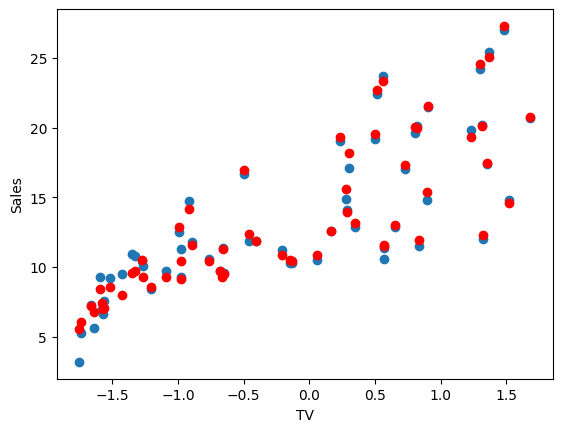

In [33]:
plt.scatter(X_test.T[0],y_test)
plt.scatter(X_test.T[0],preds,color='red')
plt.xlabel('TV')
plt.ylabel('Sales')
plt.show()

In [36]:
lasso.score(X_test,y_test)

0.9869787962811952

# ElasticNet cv

In [40]:
from sklearn.linear_model import ElasticNetCV

elasticnet= ElasticNetCV( l1_ratio=[.1, .5, .7,.9, .95, .99, 1],n_alphas=100,max_iter=1_000000 )
elasticnet.fit(X_train,y_train)

ElasticNetCV(l1_ratio=[0.1, 0.5, 0.7, 0.9, 0.95, 0.99, 1], max_iter=1000000)

In [41]:
elasticnet.score(X_test,y_test)

0.9869787962811952

In [45]:
elasticnet.l1_ratio_

np.float64(1.0)

In [46]:
y_preds=elasticnet.predict(X_test)

In [47]:
MAE=mean_absolute_error(y_test,y_preds)
RMSE= np.sqrt(mean_squared_error(y_test,preds))
MAE,RMSE

(0.4335034618590074, np.float64(0.6063140748984036))